In [3]:

# Books Recommender System — Exploratory Data Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = (
    "/Users/hariharakrishnan/Downloads/"
    "Books-Recommender-System/artifacts/dataset/"
    "clean_data/clean_data.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (59850, 9)


,user_id,ISBN,rating,title,author,year,publisher,image_url,num_of_rating
0,277427,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,82
1,3363,002542730X,0,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,82
2,11676,002542730X,6,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,82
3,12538,002542730X,10,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,82
4,13552,002542730X,0,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &amp; Sons Inc,http://images.amazon.com/images/P/002542730X.0...,82


In [2]:

# 1. Check missing values
print("Missing values in each column:")
display(df.isnull().sum())

# 2. Check exact duplicate rows
print("Number of exact duplicate rows:", df.duplicated().sum())

# 3. Check repeated user-book combinations
print(
    "Repeated user-book pairs:",
    df.duplicated(subset=["user_id", "ISBN"]).sum()
)

# 4. Check unique values
print("Unique users:", df["user_id"].nunique())
print("Unique books:", df["ISBN"].nunique())

# 5. Inspect rating values
print("\nRating value counts:")
display(df["rating"].value_counts().sort_index())

# 6. Inspect publication years
print("\nPublication year summary:")
display(df["year"].describe())

print("Records with year 0:", (df["year"] == 0).sum())


Missing values in each column:


user_id          0
ISBN             0
rating           0
title            0
author           0
year             0
publisher        0
image_url        0
num_of_rating    0
dtype: int64

Number of exact duplicate rows: 0
Repeated user-book pairs: 0
Unique users: 888
Unique books: 2144

Rating value counts:


rating
0     44908
1        62
2        61
3       109
4       200
5      1378
6       923
7      2247
8      3632
9      2973
10     3357
Name: count, dtype: int64


Publication year summary:


count    59850.000000
mean      1990.634470
std        111.588628
min          0.000000
25%       1994.000000
50%       1998.000000
75%       2001.000000
max       2010.000000
Name: year, dtype: float64

Records with year 0: 187


Total records: 59,850
Zero ratings: 44,908 (75.03%)
Nonzero ratings: 14,942 (24.97%)


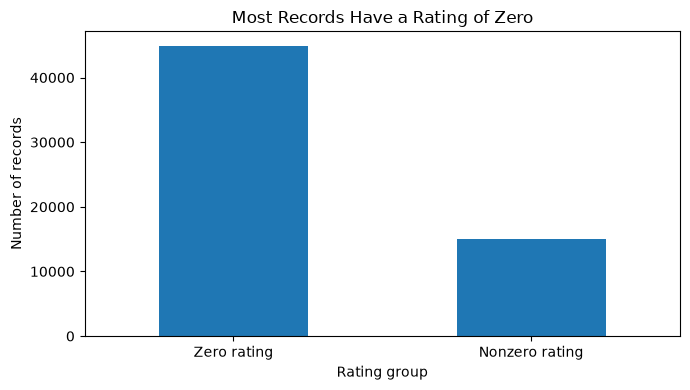

In [4]:

# Compare zero ratings with nonzero ratings

zero_count = (df["rating"] == 0).sum()
nonzero_count = (df["rating"] != 0).sum()
total_count = len(df)

print(f"Total records: {total_count:,}")
print(f"Zero ratings: {zero_count:,} ({zero_count / total_count:.2%})")
print(f"Nonzero ratings: {nonzero_count:,} ({nonzero_count / total_count:.2%})")

rating_groups = pd.Series({
    "Zero rating": zero_count,
    "Nonzero rating": nonzero_count
})

ax = rating_groups.plot(kind="bar", figsize=(7, 4))
ax.set_title("Most Records Have a Rating of Zero")
ax.set_xlabel("Rating group")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


Summary of number of ratings per book:


count    2144.000000
mean       86.555037
std        39.752944
min        50.000000
25%        59.000000
50%        73.000000
75%        99.000000
max       363.000000
Name: num_of_rating, dtype: float64

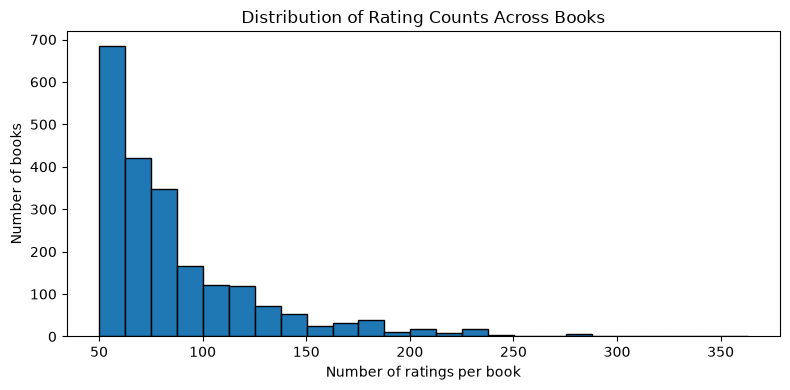

In [5]:

# Explore how frequently books are rated

book_counts = df.drop_duplicates(subset="ISBN")["num_of_rating"]

print("Summary of number of ratings per book:")
display(book_counts.describe())

plt.figure(figsize=(8, 4))
plt.hist(book_counts.dropna(), bins=25, edgecolor="black")
plt.title("Distribution of Rating Counts Across Books")
plt.xlabel("Number of ratings per book")
plt.ylabel("Number of books")
plt.tight_layout()
plt.show()



## EDA Findings: Rating Activity and Book Popularity

### 1. Zero and Nonzero Ratings

The dataset contains 59,850 records. Among them, 44,908 records (75.03%) have a rating of zero, while 14,942 records (24.97%) have a nonzero rating. This shows that zero ratings make up the majority of records in the dataset.

However, the meaning of a zero rating has not yet been verified from the original data source. Therefore, zero ratings should not automatically be interpreted as users giving books a rating of zero or as missing ratings.

### 2. Distribution of Ratings per Book

The dataset contains 2,144 unique books. The number of ratings per book has a mean of approximately 86.56 and a median of 73. The minimum is 50, the third quartile is 99, and the maximum is 363.

The histogram shows a right-skewed distribution: many books have relatively fewer ratings, while a smaller number have substantially more ratings. This suggests that rating activity is not evenly distributed across books.

### 3. Implications for the Project

These findings are relevant to a book recommendation system because rating activity may affect how much information is available about each book. Before building recommendations, the meaning of zero ratings should be verified, and the limitations caused by differences in rating activity should be considered.


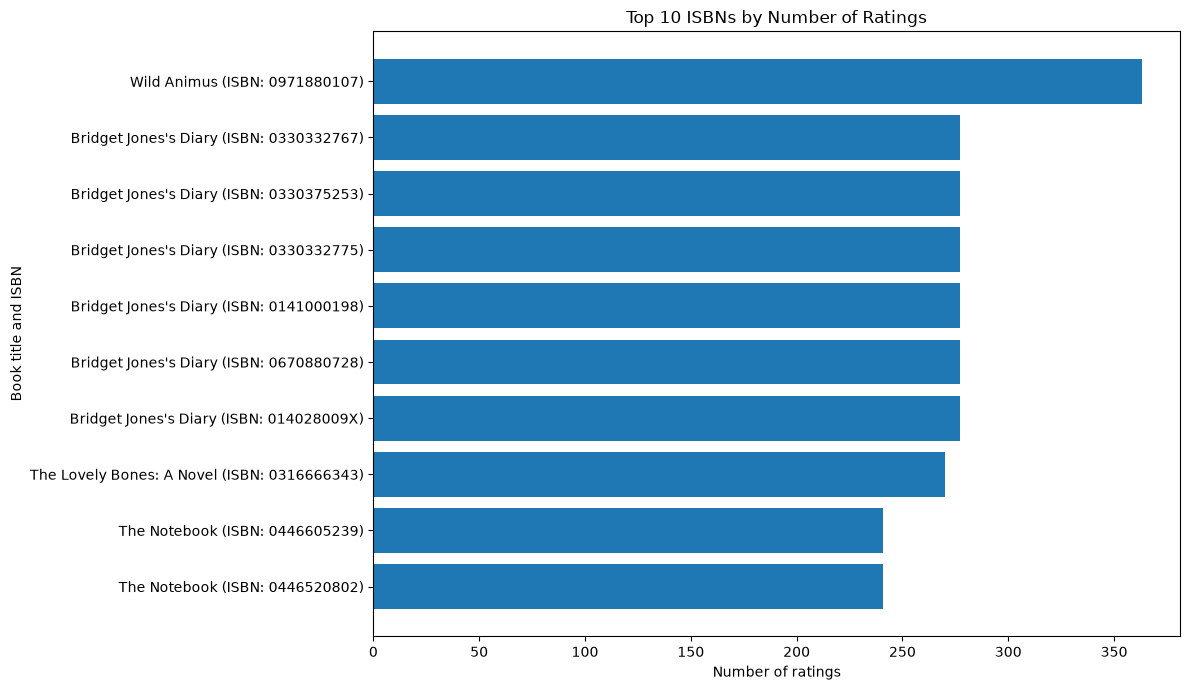

In [8]:

# Top 10 ISBNs by number of ratings, with unique labels

book_info = df.drop_duplicates(subset="ISBN").copy()

top_books = (
    book_info.nlargest(10, "num_of_rating")
    .copy()
)

top_books["label"] = (
    top_books["title"].fillna("Unknown title").astype(str)
    + " (ISBN: "
    + top_books["ISBN"].astype(str)
    + ")"
)

top_books = top_books.sort_values("num_of_rating", ascending=True)

plt.figure(figsize=(12, 7))
plt.barh(top_books["label"], top_books["num_of_rating"])

plt.title("Top 10 ISBNs by Number of Ratings")
plt.xlabel("Number of ratings")
plt.ylabel("Book title and ISBN")
plt.tight_layout()
plt.show()


In [9]:

print("Unique ISBNs in book_info:", book_info["ISBN"].nunique())
print("Rows in top_books:", len(top_books))

display(
    top_books[["title", "ISBN", "num_of_rating"]]
    .sort_values("num_of_rating", ascending=False)
)


Unique ISBNs in book_info: 2144
Rows in top_books: 10


,title,ISBN,num_of_rating
8804,Wild Animus,0971880107,363
23582,Bridget Jones's Diary,014028009X,277
23694,Bridget Jones's Diary,0670880728,277
23726,Bridget Jones's Diary,0141000198,277
23778,Bridget Jones's Diary,0330332775,277
23803,Bridget Jones's Diary,0330375253,277
23817,Bridget Jones's Diary,0330332767,277
1598,The Lovely Bones: A Novel,0316666343,270
19095,The Notebook,0446520802,241
19135,The Notebook,0446605239,241



### 4. Books with the Highest Rating Counts

The horizontal bar chart compares the 10 books with the highest numbers of ratings in the dataset. The book with the highest rating count has substantially more ratings than the other displayed books.

This chart helps identify books with greater rating activity. However, the number of ratings does not necessarily indicate that a book is better or more highly rated. It measures rating activity, not average reader satisfaction.


In [10]:

# Additional data-quality checks

print("Distinct rating values:")
print(sorted(df["rating"].dropna().unique()))

print("\nRows with publication year 0:")
print((df["year"] == 0).sum())

print("\nUnique ISBNs with publication year 0:")
print(df.loc[df["year"] == 0, "ISBN"].nunique())

print("\nMissing values by column:")
display(df.isnull().sum())

print("\nData types:")
display(df.dtypes)


Distinct rating values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Rows with publication year 0:
187

Unique ISBNs with publication year 0:
35

Missing values by column:


user_id          0
ISBN             0
rating           0
title            0
author           0
year             0
publisher        0
image_url        0
num_of_rating    0
dtype: int64


Data types:


user_id          int64
ISBN               str
rating           int64
title              str
author             str
year             int64
publisher          str
image_url          str
num_of_rating    int64
dtype: object


## Data Quality Assessment and Preparation Decisions

### Missing Values and Duplicates

The dataset contains 59,850 records and nine columns. The missing-value check returned zero missing values for every column. Earlier checks also found zero exact duplicate rows and zero repeated user-book pairs.

### Rating Values

The rating column contains integer values from 0 to 10. A total of 44,908 records (75.03%) have a rating of zero, while 14,942 records (24.97%) have a nonzero rating.

Although the dataset has no explicit missing values in the rating column, the meaning of zero ratings has not been verified. Therefore, zero ratings will not automatically be removed or treated as missing without evidence from the data source.

### Publication Year

There are 187 records with a publication year of zero, covering 35 unique ISBNs. These values require further investigation because zero may represent an unavailable or unknown publication year. They will be retained until the source meaning and an appropriate handling decision are established.

### Preparation Decisions

The initial checks did not identify explicit missing values, exact duplicate rows, or repeated user-book pairs. Therefore, no imputation or duplicate removal is justified by these checks alone. The zero-rating and publication-year issues will be documented and investigated before any transformation is applied.


In [12]:

# Check whether book titles map to multiple ISBNs

title_isbn_counts = (
    df.groupby("title")["ISBN"]
    .nunique()
    .sort_values(ascending=False)
)

print("Titles associated with more than one ISBN:")
display(title_isbn_counts[title_isbn_counts > 1].head(10))

print(
    "\nNumber of titles associated with multiple ISBNs:",
    (title_isbn_counts > 1).sum()
)


Titles associated with more than one ISBN:


title
The Secret Garden      16
Wuthering Heights      14
Pride and Prejudice    13
The Gift               12
The Promise            11
Dreamcatcher           10
Matilda                10
Carrie                 10
Homecoming             10
Beloved                 9
Name: ISBN, dtype: int64


Number of titles associated with multiple ISBNs: 551



### Multiple ISBNs for the Same Book Title

The analysis found that 551 distinct book titles are associated with more than one ISBN. The Secret Garden has 16 ISBNs, Wuthering Heights has 14, and Pride and Prejudice has 13.

This finding shows that multiple ISBNs can be associated with the same title in the dataset. These records may represent different editions or publication formats, although this has not been verified for every record.

For the recommendation system, title and ISBN should be treated as different identifiers. Counting each ISBN as a completely different book may result in repeated titles in the recommendations. Therefore, the app should clearly distinguish publication records from book titles, and duplicate-title handling should be considered when presenting recommendations.



## Overall EDA Summary

The initial exploratory data analysis examined 59,850 records, 2,144 unique ISBNs, and 888 unique users. The dataset has no explicit missing values, exact duplicate rows, or repeated user-book pairs based on the checks performed.

The rating distribution is imbalanced: 75.03% of records have a rating of zero, while 24.97% have a nonzero rating. The number of ratings per ISBN is right-skewed, with a median of 73 and a maximum of 363. The analysis also identified 187 records with publication year zero and 551 titles associated with multiple ISBNs.

These findings highlight important considerations for building a book recommendation system. The meaning of zero ratings and publication year zero needs verification, and multiple ISBNs for the same title must be considered when displaying book results. The current analysis is descriptive and does not establish that rating counts indicate book quality or that any particular recommendation method will perform well.
